# Multimodal Movie Genre Classification from Posters and Plot Summaries (MM-IMDb)

**Group 17**: Rishit Pandya, Kush Patel, Sarvam Gami, Deep Patel

**Overview**:
This notebook implements the solution described in our proposal. Each movie in MM-IMDb (Arevalo et al., 2017) has a poster (image) and a plot summary (text), and the task is to predict all of its genres (multi-label, 23 classes). Posters are encoded with a frozen EfficientNet-B0 and plots with a frozen, mean-pooled BERT. On top of these features we train and compare two unimodal baselines and three fusion strategies: **early fusion** (concatenation), **late fusion** (weighted averaging of unimodal predictions) and **intermediate attention-based fusion** with a **Gated Multimodal Unit** (GMU). All models are evaluated with several metrics on the official test set, checked for overfitting, analysed per genre, for failure cases and for bias across countries, languages and release periods.

## README: how to run this notebook

| file / folder | content |
|---|---|
| `mmimdb.tar.gz` | The original MM-IMDb release (about 8 GB), downloaded on the first run if not present. |
| `mmimdb/` | Extracted dataset: `<id>.jpeg` poster and `<id>.json` metadata per movie, plus `split.json` (official split). |
| `visual_features.pt`, `text_features.pt` | Frozen EfficientNet-B0 and BERT features for every movie, with extraction times. Created once (about 20 to 30 min on a T4 GPU), then loaded from cache. |
| `results/` | All result tables (CSV) and figures (PNG) used in the report. |

**To reproduce:** *Kernel → Restart Kernel and Run All Cells.* On Colab select a T4 GPU first; the notebook mounts Google Drive automatically so the archive and feature caches survive between sessions. All randomness is seeded with 0. Training all models takes a few minutes once the features exist.

**Data source.** https://archive.org/download/mmimdb/mmimdb.tar.gz, used for non-commercial academic research only and not redistributed.

In [1]:
# install some relevant packages
!pip install transformers torchvision scikit-learn --quiet

In [2]:
import os, sys, glob, json, time, tarfile, random, platform
import urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics import f1_score, average_precision_score, hamming_loss

# Set seeds for reproducibility
random.seed(0)
np.random.seed(0)
torch.manual_seed(0)

device = "cuda" if torch.cuda.is_available() else "cpu"
GPU_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else f"CPU ({platform.processor()})"
print("Device:", device, "|", GPU_NAME)
print("Python", sys.version.split()[0], "| torch", torch.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

Device: cuda | Tesla T4
Python 3.13.16 | torch 2.14.1+cu130 | numpy 2.4.6 | pandas 2.2.3


## Section 1: Loading the Dataset

**Step 1: Paths, download and extraction**

On Colab the archive and the feature caches are stored in Google Drive (they survive a disconnect), while the extracted dataset goes to Colab's fast local disk. On any other Jupyter environment everything is kept next to the notebook. As in the practicals, each step checks whether its output already exists, so the 8 GB download and the extraction only happen once.

In [3]:
# ---- Paths ----
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK_DIR = "/content/drive/MyDrive/mmimdb_project"   # archive + caches (persistent)
    DATA_ROOT = "/content"                                # extracted data (fast local disk)
else:
    WORK_DIR = "."
    DATA_ROOT = "."
os.makedirs(WORK_DIR, exist_ok=True)
RESULTS_DIR = os.path.join(WORK_DIR, "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

TAR_PATH = os.path.join(WORK_DIR, "mmimdb.tar.gz")
TAR_URL = "https://archive.org/download/mmimdb/mmimdb.tar.gz"


def find_split_file():
    # Look only a few levels deep so we never crawl the whole Google Drive.
    patterns = ["split.json", "*/split.json", "*/*/split.json"]
    return [p for pat in patterns for p in glob.glob(os.path.join(DATA_ROOT, pat))]


def show_progress(block_num, block_size, total_size):
    if block_num % 8000 == 0 and total_size > 0:
        print(f"  {block_num * block_size / 1e9:.1f} / {total_size / 1e9:.1f} GB")


# ---- Download the archive if neither the archive nor the extracted folder exists ----
if not find_split_file() and not os.path.exists(TAR_PATH):
    print(f"Downloading {TAR_URL} (about 8 GB, only needed once) ...")
    urllib.request.urlretrieve(TAR_URL, TAR_PATH, reporthook=show_progress)

# ---- Extract the archive if it hasn't been extracted yet ----
if not find_split_file() and os.path.exists(TAR_PATH):
    print(f"Extracting {TAR_PATH} ...")
    t0 = time.time()
    with tarfile.open(TAR_PATH) as tf:
        try:
            tf.extractall(DATA_ROOT, filter="data")
        except TypeError:
            tf.extractall(DATA_ROOT)
    print(f"Extracted in {(time.time() - t0) / 60:.1f} min")

found = find_split_file()
assert found, "split.json not found: check the download or DATA_ROOT"
SPLIT_FILE = found[0]
DATA_DIR = os.path.dirname(SPLIT_FILE)
print("DATA_DIR:", DATA_DIR, "| WORK_DIR:", WORK_DIR)

Mounted at /content/drive
Extracting /content/drive/MyDrive/mmimdb_project/mmimdb.tar.gz ...
Extracted in 3.9 min
DATA_DIR: /content/mmimdb | WORK_DIR: /content/drive/MyDrive/mmimdb_project


**Step 2: One table with both modalities and the labels**

Each metadata file is read into one row, with the poster path and the official split attached. For movies with several plot versions the longest is kept (Kiela et al., 2019). Release year, countries and languages are kept for the bias analysis in Section 6.

In [4]:
with open(SPLIT_FILE) as f:
    split = json.load(f)
id_to_split = {str(mid): name for name, ids in split.items() for mid in ids}
json_paths = [p for p in glob.glob(os.path.join(DATA_DIR, "**", "*.json"), recursive=True)
              if os.path.basename(p) != "split.json"]


def as_list(value):
    if value is None:
        return []
    return value if isinstance(value, list) else [value]


def read_movie(path):
    # Read one metadata file. Returns None (and reports the failure) if the file is broken.
    try:
        with open(path, encoding="utf-8") as f:
            meta = json.load(f)
    except Exception as e:
        print(f"Unreadable metadata file: {path} ({e})")
        return None
    movie_id = os.path.splitext(os.path.basename(path))[0]
    plots = [p for p in as_list(meta.get("plot")) if isinstance(p, str) and p.strip()]
    image_path = os.path.splitext(path)[0] + ".jpeg"
    if not os.path.exists(image_path) and os.path.exists(os.path.splitext(path)[0] + ".jpg"):
        image_path = os.path.splitext(path)[0] + ".jpg"
    return {"movie_id": movie_id, "title": meta.get("title", ""),
            "plot": max(plots, key=len) if plots else "",
            "genres": as_list(meta.get("genres")), "year": meta.get("year"),
            "countries": as_list(meta.get("countries")), "languages": as_list(meta.get("languages")),
            "image_path": image_path, "split": id_to_split.get(movie_id, "not in split")}


t0 = time.time()
records = [read_movie(p) for p in json_paths]
movies = pd.DataFrame([r for r in records if r is not None])
movies["year"] = pd.to_numeric(movies["year"], errors="coerce")
print(f"Read {len(movies)} movies in {time.time() - t0:.1f} s   broken metadata files: {sum(r is None for r in records)}")
display(movies.head(3))

Read 25959 movies in 50.3 s   broken metadata files: 0


,movie_id,title,plot,genres,year,countries,languages,image_path,split
0,0126816,Blackjack,"After saving Casey, a daughter of his friend, ...","[Action, Thriller]",1998,"[Canada, USA]",[English],/content/mmimdb/dataset/0126816.jpeg,train
1,0107438,Look Who's Talking Now,Mikey and Julie are now older and no longer du...,"[Comedy, Family, Romance]",1993,[USA],[English],/content/mmimdb/dataset/0107438.jpeg,test
2,1524539,Harishchandrachi Factory,Dadasaheb Phalke had abandoned a well establis...,"[Biography, Comedy, Drama, History]",2009,[India],[Marathi],/content/mmimdb/dataset/1524539.jpeg,test


## Section 2: Data Quality Assessment and Preprocessing

**Step 3: Cleaning, label filtering and duplicate removal**

The initial analysis (see proposal) found no corrupted posters or broken files, 14 duplicated plots and a strong genre imbalance (Drama vs Film-Noir, ratio 41). The preprocessing below therefore: (1) removes HTML remnants and extra whitespace from plots; (2) keeps the 23 genres used in the literature, dropping News, Adult, Talk-Show and Reality-TV (Arevalo et al., 2017); (3) keeps only movies with a poster, a plot and at least one genre; (4) removes duplicated plots, keeping the copy in the earliest split (train before dev before test), so that no identical plot appears in both training and evaluation data.

In [5]:
RARE_GENRES = {"News", "Adult", "Talk-Show", "Reality-TV"}

movies["plot_clean"] = (movies["plot"].str.replace(r"<[^>]+>", " ", regex=True)
                        .str.replace(r"\s+", " ", regex=True).str.strip())
movies["genres_23"] = movies["genres"].map(lambda gs: [g for g in gs if g not in RARE_GENRES])
movies["has_image"] = movies["image_path"].map(os.path.exists)

complete = (movies["has_image"] & (movies["plot_clean"] != "") &
            (movies["genres_23"].map(len) > 0) & movies["split"].isin(["train", "dev", "test"]))
data = movies[complete].copy()

# ---- Duplicated plots: keep the copy in the earliest split ----
data["split_rank"] = data["split"].map({"train": 0, "dev": 1, "test": 2})
data = data.sort_values(["split_rank", "movie_id"])
dup_mask = data.duplicated("plot_clean", keep="first")
removed_duplicates = data[dup_mask]
data = data[~dup_mask].sort_values("movie_id").reset_index(drop=True)

mlb = MultiLabelBinarizer()
Y = mlb.fit_transform(data["genres_23"]).astype(np.float32)
GENRES = list(mlb.classes_)
masks = {s: (data["split"] == s).values for s in ["train", "dev", "test"]}

prep_table = pd.DataFrame({
    "step": ["raw movies", "complete (poster + plot + >=1 of 23 genres)", "duplicated plots removed", "final dataset"],
    "movies": [len(movies), int(complete.sum()), len(removed_duplicates), len(data)]})
display(prep_table)
print("Duplicates removed per split:", removed_duplicates["split"].value_counts().to_dict())
print("Final split sizes:", {s: int(m.sum()) for s, m in masks.items()})
print(f"Genres: {len(GENRES)}   label cardinality: {Y.sum(1).mean():.2f}")

,step,movies
0,raw movies,25959
1,complete (poster + plot + >=1 of 23 genres),25959
2,duplicated plots removed,14
3,final dataset,25945


Duplicates removed per split: {'test': 9, 'train': 3, 'dev': 2}
Final split sizes: {'train': 15549, 'dev': 2606, 'test': 7790}
Genres: 23   label cardinality: 2.48


**Step 4: Modality-specific preprocessing**

*Posters.* Converted to RGB (some files are greyscale or CMYK), resized to 224 × 224 and normalised with ImageNet statistics, which is what EfficientNet-B0 was trained on. Some posters are very large (over 10,000 pixels on one side), so JPEG files are decoded at reduced resolution with PIL's `draft` mode before resizing; this gives the same 224 × 224 input but cuts decoding time substantially. Images are loaded in parallel with a `DataLoader`.

*Plots.* Tokenised with the BERT WordPiece tokenizer (lower-casing is part of `bert-base-uncased`), truncated at 512 tokens (the model limit). Plots are sorted by length before batching so each batch is padded only to its own longest plot, which reduces wasted computation. Mixed precision (float16) inference is used on the GPU for both encoders.

In [6]:
from torchvision import transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

img_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])


class PosterDataset(Dataset):
    # Loads one poster per item. Unreadable files return a black image and ok = 0.
    def __init__(self, paths):
        self.paths = list(paths)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        try:
            with Image.open(self.paths[i]) as img:
                img.draft("RGB", (320, 320))   # fast reduced-size JPEG decoding
                return img_transform(img.convert("RGB")), 1
        except Exception:
            return torch.zeros(3, 224, 224), 0

## Section 3: Feature Extraction

**Step 5: Visual features (EfficientNet-B0)**

EfficientNet-B0 (Tan & Le, 2019) pretrained on ImageNet, with the classifier removed, gives a 1,280-dimensional vector per poster. The encoder is frozen: with about 15,500 training movies, fine-tuning the full network would risk overfitting and would not fit the GPU budget, while frozen features let every fusion model train in seconds. Features are cached together with the movie ids, so the cache is only reused if it matches the current dataset.

In [7]:
def load_cache(path):
    # Returns the cache only if it was built for exactly the current list of movies.
    if os.path.exists(path):
        cache = torch.load(path)
        if cache["ids"] == list(data["movie_id"]):
            return cache
        print(f"{path} does not match the current dataset, recomputing")
    return None


VIS_CACHE = os.path.join(WORK_DIR, "visual_features.pt")
cache = load_cache(VIS_CACHE)
if cache is None:
    cnn = efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1)
    cnn.classifier = nn.Identity()
    cnn = cnn.eval().to(device)
    loader = DataLoader(PosterDataset(data["image_path"]), batch_size=64, shuffle=False, num_workers=2)
    feats, oks = [], []
    t0 = time.time()
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16, enabled=(device == "cuda")):
        for b, (x, ok) in enumerate(loader):
            feats.append(cnn(x.to(device)).float().cpu())
            oks.append(ok)
            if b % 50 == 0:
                print(f"  batch {b}/{len(loader)}  {time.time() - t0:.0f} s")
    cache = {"ids": list(data["movie_id"]), "feats": torch.cat(feats), "ok": torch.cat(oks),
             "seconds": time.time() - t0}
    torch.save(cache, VIS_CACHE)
    del cnn

X_img = cache["feats"].numpy()
t_img = cache["seconds"]
print(f"Visual features: {X_img.shape}   extraction time: {t_img / 60:.1f} min   unreadable posters: {int((cache['ok'] == 0).sum())}")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 169MB/s]


  batch 0/406  8 s
  batch 50/406  29 s
  batch 100/406  49 s
  batch 150/406  73 s
  batch 200/406  91 s
  batch 250/406  112 s
  batch 300/406  145 s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (174960000 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (95616768 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (99331758 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (97888494 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (94770000 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS

  batch 350/406  194 s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (97200000 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (99083998 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (97200000 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (92984898 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (93555000 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS 

  batch 400/406  269 s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (97212000 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (101769871 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


Visual features: (25945, 1280)   extraction time: 4.6 min   unreadable posters: 0


**Step 6: Text features (BERT, mask-aware mean pooling)**

BERT (Devlin et al., 2019) token embeddings from the last layer are averaged over real tokens only (padding excluded through the attention mask), giving a 768-dimensional vector per plot. Mean pooling was used in Assignment 2 and is a stronger sentence representation than the raw [CLS] token for a frozen BERT (Reimers & Gurevych, 2019).

In [8]:
from transformers import AutoTokenizer, AutoModel

BERT_NAME = "bert-base-uncased"
MAX_LEN = 512

TXT_CACHE = os.path.join(WORK_DIR, "text_features.pt")
cache = load_cache(TXT_CACHE)
if cache is None:
    tokenizer = AutoTokenizer.from_pretrained(BERT_NAME)
    bert = AutoModel.from_pretrained(BERT_NAME).eval().to(device)
    texts = list(data["plot_clean"])
    order = np.argsort([len(t) for t in texts])           # sort by length: less padding per batch
    feats = torch.zeros(len(texts), 768)
    n_truncated = 0
    t0 = time.time()
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16, enabled=(device == "cuda")):
        for b, i in enumerate(range(0, len(texts), 64)):
            idx = order[i:i + 64]
            enc = tokenizer([texts[j] for j in idx], padding=True, truncation=True,
                            max_length=MAX_LEN, return_tensors="pt").to(device)
            n_truncated += int((enc["attention_mask"].sum(1) == MAX_LEN).sum())
            hidden = bert(**enc).last_hidden_state.float()
            mask = enc["attention_mask"].unsqueeze(-1).float()
            feats[torch.as_tensor(idx)] = ((hidden * mask).sum(1) / mask.sum(1)).cpu()
            if b % 50 == 0:
                print(f"  batch {b}/{len(texts) // 64 + 1}  {time.time() - t0:.0f} s")
    cache = {"ids": list(data["movie_id"]), "feats": feats, "n_truncated": n_truncated,
             "seconds": time.time() - t0}
    torch.save(cache, TXT_CACHE)
    del bert

X_txt = cache["feats"].numpy()
t_txt = cache["seconds"]
print(f"Text features: {X_txt.shape}   extraction time: {t_txt / 60:.1f} min   plots truncated at {MAX_LEN} tokens: {cache['n_truncated']}")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  batch 0/406  1 s
  batch 50/406  3 s
  batch 100/406  6 s
  batch 150/406  11 s
  batch 200/406  17 s
  batch 250/406  25 s
  batch 300/406  36 s
  batch 350/406  48 s
  batch 400/406  68 s
Text features: (25945, 768)   extraction time: 1.2 min   plots truncated at 512 tokens: 124


**Step 7: Standardisation and tensors**

Each feature dimension is standardised with the mean and standard deviation of the **training set only**, so no information from the validation or test sets leaks into training. The two modalities have very different scales, and standardising them puts them on equal footing before fusion.

In [9]:
def standardise(X):
    mu, sd = X[masks["train"]].mean(0), X[masks["train"]].std(0) + 1e-6
    return (X - mu) / sd


Xi_all, Xt_all = standardise(X_img), standardise(X_txt)
T = lambda a: torch.tensor(a, dtype=torch.float32)
Xi = {s: T(Xi_all[m]) for s, m in masks.items()}
Xt = {s: T(Xt_all[m]) for s, m in masks.items()}
Ys = {s: Y[m] for s, m in masks.items()}

# Positive-class weights for the loss: sqrt(negatives / positives) per genre on the training set.
# The square root softens the weight of very rare genres (Film-Noir would otherwise get about 75).
pos = Ys["train"].sum(0)
POS_WEIGHT = T(np.sqrt((len(Ys["train"]) - pos) / pos))
print(pd.Series(POS_WEIGHT.numpy(), index=GENRES).round(2).sort_values(ascending=False).head(5).to_dict())

{'Film-Noir': 8.720000267028809, 'Short': 7.369999885559082, 'Sport': 6.329999923706055, 'Western': 5.980000019073486, 'Musical': 5.46999979019165}


## Section 4: Models

**Step 8: Model definitions**

All models take the poster features and the plot features and output 23 logits (one per genre), trained with a weighted binary cross-entropy loss (multi-label classification). They share the same hidden size (512), dropout (0.3) and training procedure, so differences between them come from the fusion strategy only.

| model | fusion type | how the modalities are combined |
|---|---|---|
| Image only, Text only | none (unimodal baseline) | one MLP on one modality |
| Early fusion | early (feature level) | features concatenated, then one MLP |
| Late fusion | late (decision level) | the two unimodal models' probabilities averaged with weight w tuned on the validation set |
| GMU | intermediate, attention-based | each modality projected to a hidden vector; a learned gate z decides per dimension how much to trust each modality: h = z · tanh(W_v x_v) + (1 − z) · tanh(W_t x_t), with z = σ(W_z [x_v; x_t]) (Arevalo et al., 2017) |

The GMU gate also makes the model interpretable: z close to 1 means the model relies on the poster, close to 0 on the plot (Step 14).

In [10]:
HIDDEN, DROPOUT = 512, 0.3
N_OUT = len(GENRES)
D_IMG, D_TXT = Xi["train"].shape[1], Xt["train"].shape[1]


class UnimodalMLP(nn.Module):
    def __init__(self, modality, in_dim):
        super().__init__()
        self.modality = modality
        self.net = nn.Sequential(nn.Dropout(0.1), nn.Linear(in_dim, HIDDEN), nn.ReLU(),
                                 nn.Dropout(DROPOUT), nn.Linear(HIDDEN, N_OUT))

    def forward(self, x_img, x_txt):
        return self.net(x_img if self.modality == "image" else x_txt)


class EarlyFusionMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Dropout(0.1), nn.Linear(D_IMG + D_TXT, HIDDEN), nn.ReLU(),
                                 nn.Dropout(DROPOUT), nn.Linear(HIDDEN, N_OUT))

    def forward(self, x_img, x_txt):
        return self.net(torch.cat([x_img, x_txt], dim=1))


class GMUClassifier(nn.Module):
    # Gated Multimodal Unit (Arevalo et al., 2017) followed by a linear classifier.
    def __init__(self):
        super().__init__()
        self.in_drop = nn.Dropout(0.1)
        self.img_proj = nn.Linear(D_IMG, HIDDEN)
        self.txt_proj = nn.Linear(D_TXT, HIDDEN)
        self.gate = nn.Linear(D_IMG + D_TXT, HIDDEN)
        self.out = nn.Sequential(nn.Dropout(DROPOUT), nn.Linear(HIDDEN, N_OUT))

    def forward(self, x_img, x_txt, return_gate=False):
        x_img, x_txt = self.in_drop(x_img), self.in_drop(x_txt)
        h_v = torch.tanh(self.img_proj(x_img))
        h_t = torch.tanh(self.txt_proj(x_txt))
        z = torch.sigmoid(self.gate(torch.cat([x_img, x_txt], dim=1)))
        logits = self.out(z * h_v + (1 - z) * h_t)
        return (logits, z) if return_gate else logits

**Step 9: Training procedure**

AdamW (learning rate 1e-3, weight decay 1e-4), batch size 256, up to 60 epochs. After every epoch the training and validation losses are recorded (both computed in evaluation mode, so dropout does not distort the comparison). **Early stopping** keeps the weights with the lowest validation loss and stops after 8 epochs without improvement, which is the main protection against overfitting; the recorded curves are used to assess it in Step 12.

In [11]:
EPOCHS, LR, WEIGHT_DECAY, BATCH, PATIENCE = 60, 1e-3, 1e-4, 256, 8
eval_loss_fn = nn.BCEWithLogitsLoss(pos_weight=POS_WEIGHT)


def predict_logits(model, split_name, batch=4096):
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(Xi[split_name]), batch):
            out.append(model(Xi[split_name][i:i + batch].to(device), Xt[split_name][i:i + batch].to(device)).cpu())
    return torch.cat(out)


def predict_proba(model, split_name):
    return torch.sigmoid(predict_logits(model, split_name)).numpy()


def train_model(model, name):
    torch.manual_seed(0)
    model = model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=POS_WEIGHT.to(device))
    Ytr = T(Ys["train"])
    n = len(Ytr)
    gen = torch.Generator().manual_seed(0)
    history, best_loss, best_state, bad = [], float("inf"), None, 0
    t0 = time.time()
    for epoch in range(1, EPOCHS + 1):
        model.train()
        perm = torch.randperm(n, generator=gen)
        for i in range(0, n, BATCH):
            idx = perm[i:i + BATCH]
            logits = model(Xi["train"][idx].to(device), Xt["train"][idx].to(device))
            loss = loss_fn(logits, Ytr[idx].to(device))
            opt.zero_grad()
            loss.backward()
            opt.step()
        tr_loss = eval_loss_fn(predict_logits(model, "train"), Ytr).item()
        dv_loss = eval_loss_fn(predict_logits(model, "dev"), T(Ys["dev"])).item()
        history.append({"epoch": epoch, "train loss": tr_loss, "validation loss": dv_loss})
        if dv_loss < best_loss - 1e-4:
            best_loss, bad = dv_loss, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE:
                break
    model.load_state_dict(best_state)
    train_time = time.time() - t0
    best_epoch = int(np.argmin([h["validation loss"] for h in history])) + 1
    print(f"{name:<14} stopped at epoch {epoch:>2}, best epoch {best_epoch:>2}, best val loss {best_loss:.4f}, {train_time:.1f} s")
    return model, pd.DataFrame(history), train_time


models, histories, train_times = {}, {}, {}
for name, mdl in [("Image only", UnimodalMLP("image", D_IMG)),
                  ("Text only", UnimodalMLP("text", D_TXT)),
                  ("Early fusion", EarlyFusionMLP()),
                  ("GMU", GMUClassifier())]:
    models[name], histories[name], train_times[name] = train_model(mdl, name)

Image only     stopped at epoch 10, best epoch  2, best val loss 0.4910, 3.1 s
Text only      stopped at epoch 11, best epoch  3, best val loss 0.3129, 2.9 s
Early fusion   stopped at epoch 10, best epoch  2, best val loss 0.3032, 2.5 s
GMU            stopped at epoch 11, best epoch  3, best val loss 0.3041, 3.5 s


**Step 10: Late fusion and decision thresholds**

*Late fusion.* The predicted probabilities of the two unimodal models are combined as p = w · p_image + (1 − w) · p_text. The weight w is chosen on the validation set by maximising macro average precision, which does not depend on a threshold.

*Thresholds.* With 23 imbalanced genres, a single 0.5 threshold is a poor choice for rare genres. For every model, one threshold per genre is tuned on the validation set (the value in 0.05 to 0.95 that maximises that genre's F1). The test set is never used for any tuning. Results with the plain 0.5 threshold are kept for comparison (Appendix table).

Late fusion image weight w = 0.3


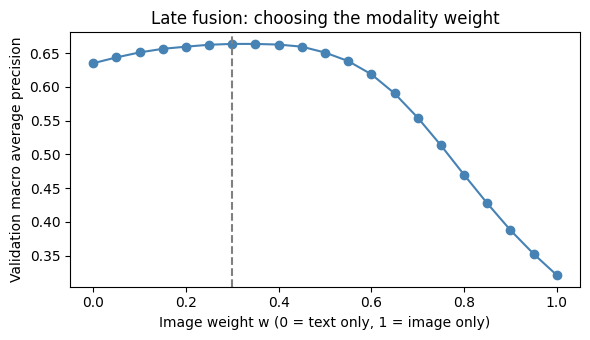

In [12]:
proba = {name: {s: predict_proba(m, s) for s in ["train", "dev", "test"]} for name, m in models.items()}

# ---- Late fusion weight tuned on the validation set ----
weights = np.round(np.arange(0, 1.01, 0.05), 2)
val_map = [average_precision_score(Ys["dev"], w * proba["Image only"]["dev"] + (1 - w) * proba["Text only"]["dev"],
                                   average="macro") for w in weights]
W_LATE = float(weights[int(np.argmax(val_map))])
proba["Late fusion"] = {s: W_LATE * proba["Image only"][s] + (1 - W_LATE) * proba["Text only"][s]
                        for s in ["train", "dev", "test"]}
train_times["Late fusion"] = train_times["Image only"] + train_times["Text only"]
print(f"Late fusion image weight w = {W_LATE}")

plt.figure(figsize=(6, 3.5))
plt.plot(weights, val_map, marker="o", color="steelblue")
plt.axvline(W_LATE, ls="--", color="grey")
plt.xlabel("Image weight w (0 = text only, 1 = image only)")
plt.ylabel("Validation macro average precision")
plt.title("Late fusion: choosing the modality weight")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "late_fusion_weight.png"), dpi=150)
plt.show()


# ---- Per-genre thresholds tuned on the validation set ----
def tune_thresholds(p_dev, y_dev, grid=np.round(np.arange(0.05, 0.96, 0.05), 2)):
    return np.array([grid[int(np.argmax([f1_score(y_dev[:, j], p_dev[:, j] >= t, zero_division=0) for t in grid]))]
                     for j in range(y_dev.shape[1])])


MODEL_ORDER = ["Image only", "Text only", "Early fusion", "Late fusion", "GMU"]
thresholds = {name: tune_thresholds(proba[name]["dev"], Ys["dev"]) for name in MODEL_ORDER}

## Section 5: Evaluation and Comparison

**Step 11: Test results with several metrics**

Six metrics are reported, because each answers a different question: **micro F1** (overall, dominated by frequent genres), **macro F1** (every genre counts equally, so it reflects rare genres), **weighted F1** (macro weighted by genre frequency, the metric used by Arevalo et al.), **samples F1** (average quality of each movie's predicted genre set), **macro mAP** (ranking quality, threshold-free) and **Hamming loss** (share of wrong genre decisions, lower is better).

In [13]:
def evaluate(y, p, th):
    pred = (p >= th).astype(int)
    return {"micro F1": f1_score(y, pred, average="micro", zero_division=0),
            "macro F1": f1_score(y, pred, average="macro", zero_division=0),
            "weighted F1": f1_score(y, pred, average="weighted", zero_division=0),
            "samples F1": f1_score(y, pred, average="samples", zero_division=0),
            "macro mAP": average_precision_score(y, p, average="macro"),
            "Hamming loss": hamming_loss(y, pred)}


test_results = pd.DataFrame({name: evaluate(Ys["test"], proba[name]["test"], thresholds[name])
                             for name in MODEL_ORDER}).T
display(test_results.round(3).style.highlight_max(axis=0, subset=test_results.columns[:-1], color="#c6efce")
        .highlight_min(axis=0, subset=["Hamming loss"], color="#c6efce").format("{:.3f}"))
test_results.round(4).to_csv(os.path.join(RESULTS_DIR, "test_results.csv"))

# Model selected on the VALIDATION set (macro F1), not on the test set
dev_macro = {name: evaluate(Ys["dev"], proba[name]["dev"], thresholds[name])["macro F1"] for name in MODEL_ORDER}
BEST = max(dev_macro, key=dev_macro.get)
print("Best model on the validation set (macro F1):", BEST)

# Reference: published results on the same test split (different encoders and training setups)
reference = pd.DataFrame({"micro F1": [0.630, 0.669], "macro F1": [0.541, 0.618]},
                         index=["GMU, Arevalo et al. (2017)", "MMBT, Kiela et al. (2019), fine-tuned BERT"])
print("\nPublished reference results:")
display(reference)

# Appendix: effect of per-genre thresholds versus a single 0.5 threshold
th_effect = pd.DataFrame({name: {"macro F1 @0.5": evaluate(Ys["test"], proba[name]["test"], 0.5)["macro F1"],
                                 "macro F1 tuned": test_results.loc[name, "macro F1"],
                                 "micro F1 @0.5": evaluate(Ys["test"], proba[name]["test"], 0.5)["micro F1"],
                                 "micro F1 tuned": test_results.loc[name, "micro F1"]}
                          for name in MODEL_ORDER}).T
print("\nAppendix: per-genre thresholds vs a fixed 0.5 threshold (test set)")
display(th_effect.round(3))
th_effect.round(4).to_csv(os.path.join(RESULTS_DIR, "threshold_effect.csv"))

,micro F1,macro F1,weighted F1,samples F1,macro mAP,Hamming loss
Image only,0.458,0.346,0.474,0.452,0.311,0.149
Text only,0.657,0.594,0.657,0.654,0.620,0.081
Early fusion,0.662,0.605,0.665,0.657,0.635,0.078
Late fusion,0.670,0.609,0.669,0.666,0.637,0.077
GMU,0.658,0.603,0.661,0.652,0.639,0.078


Best model on the validation set (macro F1): GMU

Published reference results:


,micro F1,macro F1
"GMU, Arevalo et al. (2017)",0.630,0.541
"MMBT, Kiela et al. (2019), fine-tuned BERT",0.669,0.618



Appendix: per-genre thresholds vs a fixed 0.5 threshold (test set)


,macro F1 @0.5,macro F1 tuned,micro F1 @0.5,micro F1 tuned
Image only,0.312,0.346,0.452,0.458
Text only,0.588,0.594,0.645,0.657
Early fusion,0.597,0.605,0.654,0.662
Late fusion,0.608,0.609,0.665,0.670
GMU,0.605,0.603,0.660,0.658


*Interpretation.* (Write after running.) Which model is best, by how much it beats the strongest single modality, and how close it gets to the published results. Note that micro F1 is always higher than macro F1 because frequent genres are easier.

**Step 12: Overfitting assessment**

Two checks: the training and validation loss curves for each trained model, and the gap between training and test macro F1 (same tuned thresholds).

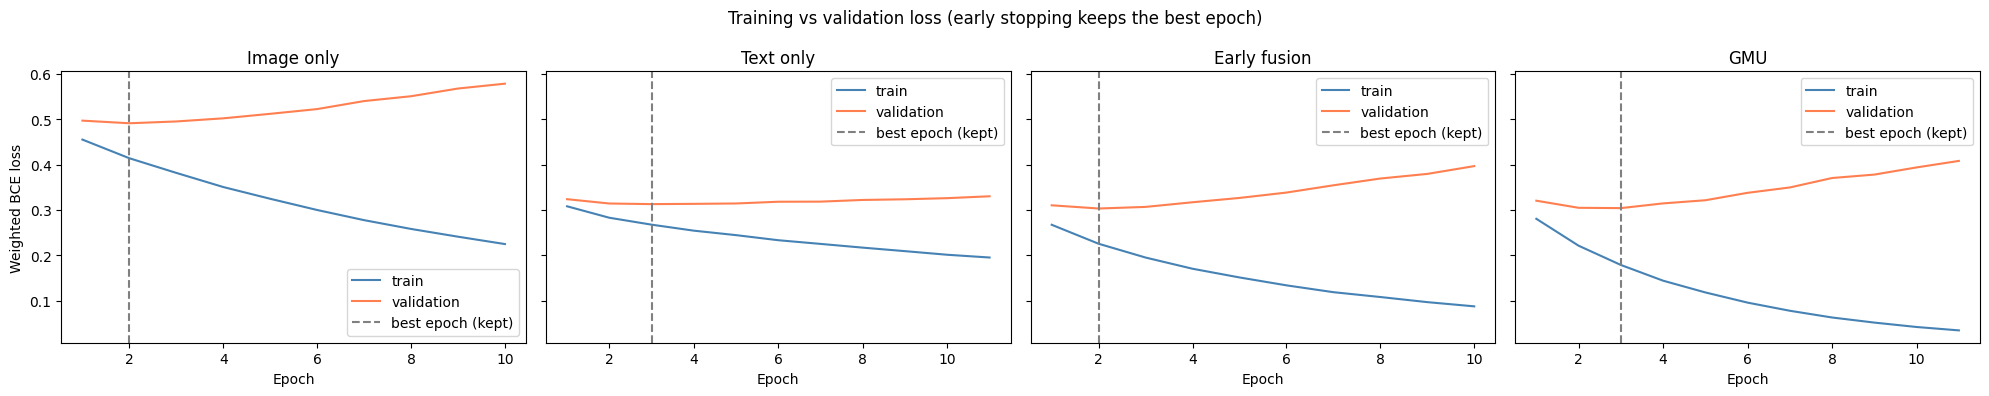

,train macro F1,test macro F1,gap (train - test)
Image only,0.468,0.346,0.123
Text only,0.651,0.594,0.057
Early fusion,0.729,0.605,0.124
Late fusion,0.687,0.609,0.078
GMU,0.803,0.603,0.199


In [14]:
trained = ["Image only", "Text only", "Early fusion", "GMU"]
fig, axes = plt.subplots(1, 4, figsize=(20, 4), sharey=True)
for ax, name in zip(axes, trained):
    h = histories[name]
    ax.plot(h["epoch"], h["train loss"], label="train", color="steelblue")
    ax.plot(h["epoch"], h["validation loss"], label="validation", color="coral")
    best = h["validation loss"].idxmin()
    ax.axvline(h.loc[best, "epoch"], ls="--", color="grey", label="best epoch (kept)")
    ax.set(title=name, xlabel="Epoch")
    ax.legend()
axes[0].set_ylabel("Weighted BCE loss")
plt.suptitle("Training vs validation loss (early stopping keeps the best epoch)")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "loss_curves.png"), dpi=150)
plt.show()

overfit = pd.DataFrame({name: {"train macro F1": evaluate(Ys["train"], proba[name]["train"], thresholds[name])["macro F1"],
                               "test macro F1": test_results.loc[name, "macro F1"]} for name in MODEL_ORDER}).T
overfit["gap (train - test)"] = overfit["train macro F1"] - overfit["test macro F1"]
display(overfit.round(3))
overfit.round(4).to_csv(os.path.join(RESULTS_DIR, "overfitting.csv"))

*Interpretation.* (Write after running.) Where the validation loss starts rising while the training loss keeps falling, the model begins to overfit; early stopping keeps the weights from before that point. Compare the train/test gaps: models with more parameters (early fusion, GMU) usually show a larger gap.

**Step 13: Efficiency**

Parameters, training time and inference time for the trainable heads. Feature extraction is shared by all models and happens once.

In [15]:
def count_params(m):
    return sum(p.numel() for p in m.parameters())


def inference_ms_per_1000(model):
    t0 = time.time()
    for _ in range(5):
        predict_logits(model, "test")
    return (time.time() - t0) / 5 / len(Ys["test"]) * 1000 * 1000


eff = {}
for name in trained:
    eff[name] = {"parameters": count_params(models[name]), "training time (s)": train_times[name],
                 "inference (ms per 1,000 movies)": inference_ms_per_1000(models[name])}
eff["Late fusion"] = {"parameters": eff["Image only"]["parameters"] + eff["Text only"]["parameters"],
                      "training time (s)": train_times["Late fusion"],
                      "inference (ms per 1,000 movies)": eff["Image only"]["inference (ms per 1,000 movies)"] +
                                                         eff["Text only"]["inference (ms per 1,000 movies)"]}
efficiency = pd.DataFrame(eff).T.loc[MODEL_ORDER]
efficiency["test macro F1"] = test_results["macro F1"]
display(efficiency.round(2))
efficiency.round(3).to_csv(os.path.join(RESULTS_DIR, "efficiency.csv"))
print(f"Shared feature extraction: EfficientNet-B0 {t_img / 60:.1f} min, BERT {t_txt / 60:.1f} min on {GPU_NAME}")

,parameters,training time (s),"inference (ms per 1,000 movies)",test macro F1
Image only,667671.0,3.06,2.61,0.35
Text only,405527.0,2.88,2.35,0.59
Early fusion,1060887.0,2.50,2.68,0.61
Late fusion,1073198.0,5.94,4.96,0.61
GMU,2110487.0,3.53,3.39,0.60


Shared feature extraction: EfficientNet-B0 4.6 min, BERT 1.2 min on Tesla T4


## Section 6: Per-genre Analysis, Failure Cases and Bias

**Step 14: Which genres benefit from fusion, and what does the GMU gate rely on?**

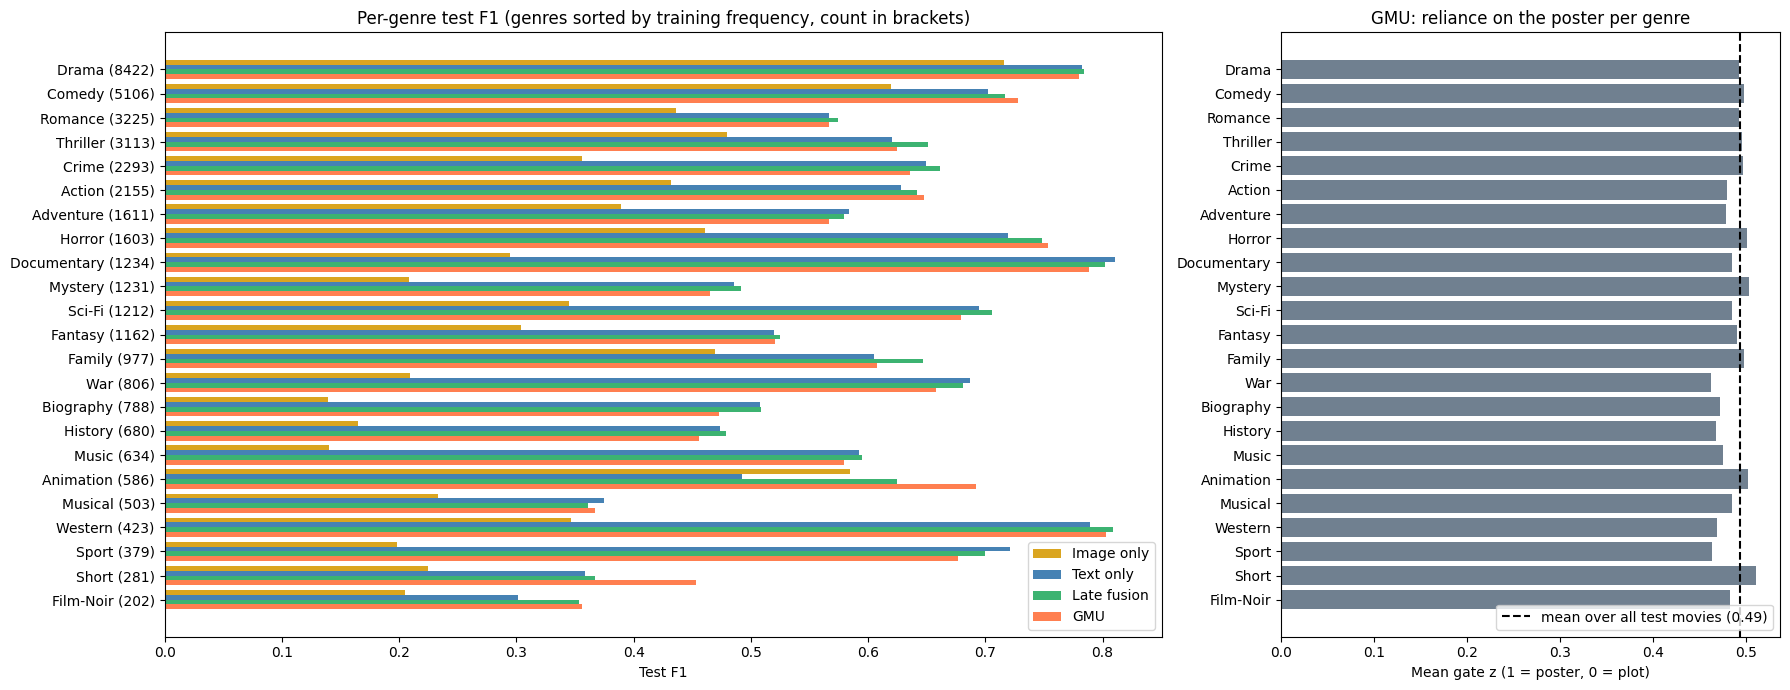

Largest F1 gains of GMU over Text only: {'Comedy': 0.026, 'Horror': 0.034, 'Film-Noir': 0.055, 'Short': 0.094, 'Animation': 0.199}
Largest F1 losses of GMU vs Text only: {'Sport': -0.044, 'Biography': -0.035, 'War': -0.029}


In [16]:
genre_freq = pd.Series(Ys["train"].sum(0), index=GENRES).sort_values(ascending=False)
per_genre = pd.DataFrame({name: f1_score(Ys["test"], proba[name]["test"] >= thresholds[name], average=None, zero_division=0)
                          for name in MODEL_ORDER}, index=GENRES).loc[genre_freq.index]
per_genre.round(4).to_csv(os.path.join(RESULTS_DIR, "per_genre_f1.csv"))

# Average GMU gate value per genre on the test set: z near 1 = relies on poster, near 0 = relies on plot
gmu = models["GMU"].eval()
with torch.no_grad():
    _, z = gmu(Xi["test"].to(device), Xt["test"].to(device), return_gate=True)
z_movie = z.mean(dim=1).cpu().numpy()
gate_per_genre = pd.Series([z_movie[Ys["test"][:, j] == 1].mean() for j in range(N_OUT)], index=GENRES).loc[genre_freq.index]

fig, axes = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={"width_ratios": [2, 1]})
y_pos = np.arange(len(GENRES))
show = ["Image only", "Text only", "Late fusion", "GMU"]
colours = ["goldenrod", "steelblue", "mediumseagreen", "coral"]
for k, (name, c) in enumerate(zip(show, colours)):
    axes[0].barh(y_pos + (k - 1.5) * 0.2, per_genre[name], height=0.2, label=name, color=c)
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels([f"{g} ({int(genre_freq[g])})" for g in genre_freq.index])
axes[0].invert_yaxis()
axes[0].set(xlabel="Test F1", title="Per-genre test F1 (genres sorted by training frequency, count in brackets)")
axes[0].legend(loc="lower right")

axes[1].barh(y_pos, gate_per_genre.values, color="slategray")
axes[1].axvline(z_movie.mean(), ls="--", color="black", label=f"mean over all test movies ({z_movie.mean():.2f})")
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(genre_freq.index)
axes[1].invert_yaxis()
axes[1].set(xlabel="Mean gate z (1 = poster, 0 = plot)", title="GMU: reliance on the poster per genre")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "per_genre_f1_and_gate.png"), dpi=150)
plt.show()

gain = (per_genre[BEST] - per_genre["Text only"]).sort_values()
print(f"Largest F1 gains of {BEST} over Text only:", gain.tail(5).round(3).to_dict())
print(f"Largest F1 losses of {BEST} vs Text only:", gain.head(3).round(3).to_dict())

*Interpretation.* (Write after running.) Which genres gain most from adding the poster (often visually distinctive genres such as Animation or Horror), which genres stay hard for every model (usually the rarest), and whether the GMU gate leans towards the poster for the same visual genres.

**Step 15: Failure cases**

We look at the most confident mistakes of the best model on the test set: movies where a genre was predicted with very high probability but is not in the label (false positive), or where a true genre received a very low probability (false negative).

,false positives,false negatives,test movies with genre
Drama,1160,752,4140
Thriller,540,610,1567
Comedy,968,562,2606
Romance,1081,534,1590
Crime,443,414,1163
Action,514,297,1043
Mystery,509,275,616
Fantasy,303,271,583


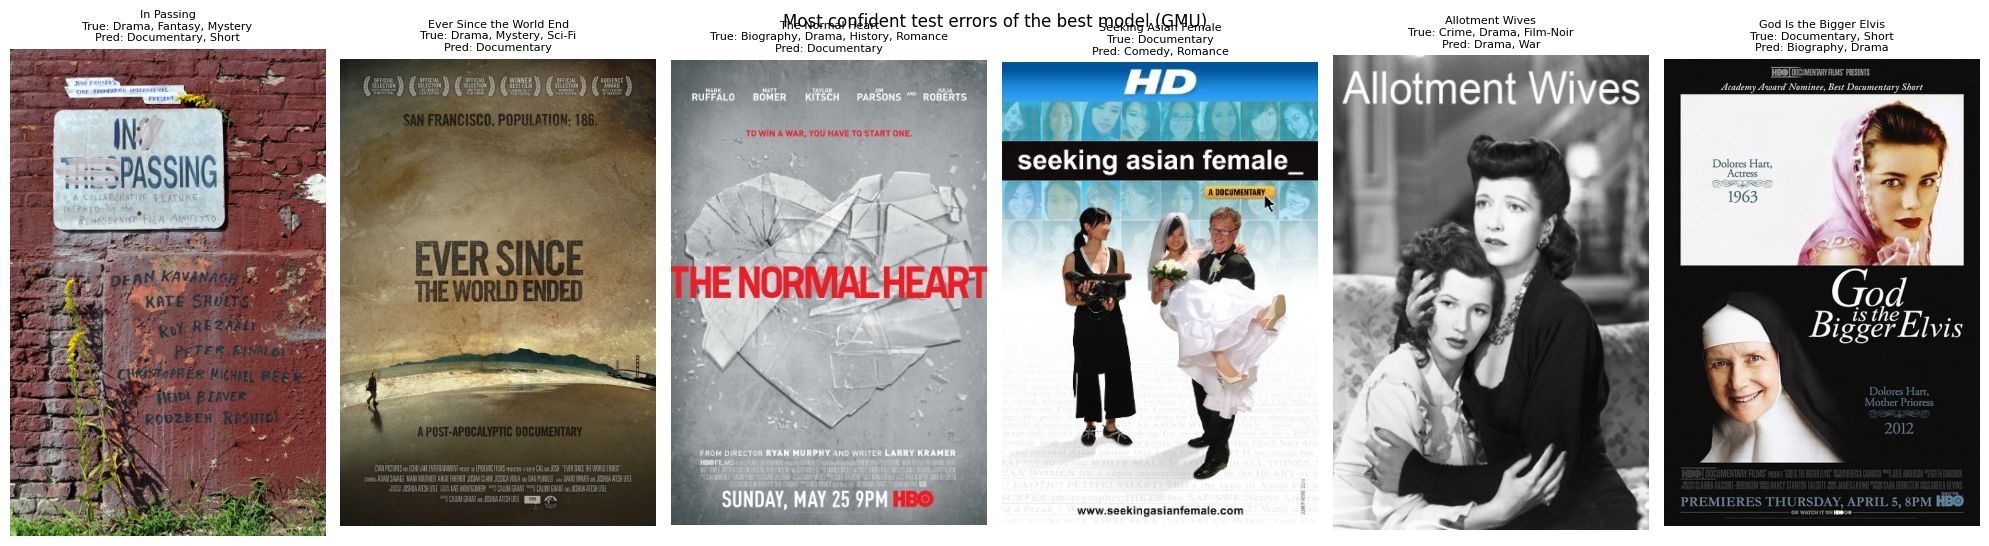

--- In Passing ---
In Passing is a collaboration between seven different filmmakers from around the world in response to Jesse Richards' 2008 Remodernist Film Manifesto....

--- Ever Since the World Ended ---
Twelve years ago, a plague swept through, wiping out most of the population; in San Francisco, only 186 people remain. Two of them use jury-rigged batteries to power a camera and make a documentary. We see a variety of approaches to survival, from the artist and engineer who trade for their needs, t...

--- The Normal Heart ---
The story of the onset of the HIV-AIDS crisis in New York City in the early 1980s, taking an unflinching look at the nation's sexual politics as gay activists and their allies in the medical community fight to expose the truth about the burgeoning epidemic to a city and nation in denial....



In [17]:
test_df = data[masks["test"]].reset_index(drop=True)
p_best = proba[BEST]["test"]
pred_best = (p_best >= thresholds[BEST]).astype(int)
y_test = Ys["test"]

# ---- Most frequent error types ----
fp = pd.Series(((pred_best == 1) & (y_test == 0)).sum(0), index=GENRES)
fn = pd.Series(((pred_best == 0) & (y_test == 1)).sum(0), index=GENRES)
display(pd.DataFrame({"false positives": fp, "false negatives": fn, "test movies with genre": y_test.sum(0).astype(int)})
        .sort_values("false negatives", ascending=False).head(8))

# ---- Six most confident mistakes: highest wrong probability or lowest probability for a true genre ----
wrong_conf = np.where(y_test == 0, p_best, 0).max(1) + np.where(y_test == 1, 1 - p_best, 0).max(1)
worst = np.argsort(-wrong_conf)[:6]
fig, axes = plt.subplots(1, 6, figsize=(20, 5.5))
for ax, i in zip(axes, worst):
    with Image.open(test_df.loc[i, "image_path"]) as img:
        img.draft("RGB", (300, 300))
        ax.imshow(img.convert("RGB"))
    true_g = ", ".join(test_df.loc[i, "genres_23"])
    pred_g = ", ".join(GENRES[j] for j in np.where(pred_best[i])[0]) or "none"
    ax.set_title(f"{str(test_df.loc[i, 'title'])[:24]}\nTrue: {true_g}\nPred: {pred_g}", fontsize=8)
    ax.axis("off")
plt.suptitle(f"Most confident test errors of the best model ({BEST})")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "failure_cases.png"), dpi=150)
plt.show()

for i in worst[:3]:
    print(f"--- {test_df.loc[i, 'title']} ---\n{test_df.loc[i, 'plot_clean'][:300]}...\n")

*Interpretation.* (Write after running.) Typical causes of errors: posters that do not reflect the genre (for example DVD covers or text-only posters), short or generic plots, subjective labels (a movie labelled Comedy whose plot reads as Drama), and genres that frequently co-occur being predicted together.

**Step 16: Bias: does performance differ across groups?**

The initial analysis showed that 57% of movies are US productions, 74% are in English and most were released after 1990. Here we test whether the best model performs worse on the under-represented groups. Micro F1 is used for the subgroups because some rare genres do not appear in small groups, which makes macro F1 unstable.

,attribute,group,test movies,micro F1,samples F1
0,Country,USA,4398,0.663,0.656
1,Country,Non-USA,3392,0.651,0.647
2,Language,Non-English,2048,0.645,0.646
3,Language,English,5742,0.662,0.654
4,Release,Before 1990,2965,0.643,0.637
5,Release,1990 or later,4825,0.667,0.661


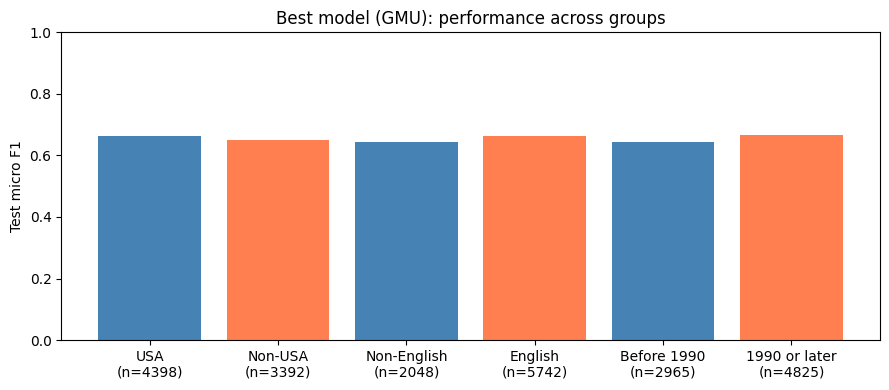

In [18]:
groups = {
    "Country": test_df["countries"].map(lambda v: "USA" if len(v) and v[0] == "USA" else "Non-USA"),
    "Language": test_df["languages"].map(lambda v: "English" if len(v) and v[0] == "English" else "Non-English"),
    "Release": test_df["year"].map(lambda y: "Before 1990" if y < 1990 else ("1990 or later" if y >= 1990 else "Unknown")),
}
rows = []
for gname, labels in groups.items():
    for value in labels.unique():
        if value == "Unknown":
            continue
        sel = (labels == value).values
        rows.append({"attribute": gname, "group": value, "test movies": int(sel.sum()),
                     "micro F1": f1_score(y_test[sel], pred_best[sel], average="micro", zero_division=0),
                     "samples F1": f1_score(y_test[sel], pred_best[sel], average="samples", zero_division=0)})
bias = pd.DataFrame(rows)
display(bias.round(3))
bias.round(4).to_csv(os.path.join(RESULTS_DIR, "bias_subgroups.csv"), index=False)

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(bias))
ax.bar(x, bias["micro F1"], color=["steelblue", "coral"] * (len(bias) // 2 + 1))
ax.set_xticks(x)
ax.set_xticklabels([f"{g}\n(n={n})" for g, n in zip(bias["group"], bias["test movies"])])
ax.set(ylabel="Test micro F1", title=f"Best model ({BEST}): performance across groups")
ax.set_ylim(0, 1)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "bias_subgroups.png"), dpi=150)
plt.show()

*Interpretation.* (Write after running.) Report the gap between each pair of groups. A lower score for non-US, non-English or older films is evidence of representation bias, since these groups are a minority of the training data. Possible mitigations for the report: re-weighting or oversampling under-represented groups, multilingual text encoders, and reporting per-group metrics before deployment.

## Summary for the Report and Slides

In [19]:
best_unimodal = test_results.loc[["Image only", "Text only"], "macro F1"].max()
summary = pd.Series({
    "Final dataset (train / dev / test)": " / ".join(str(int(m.sum())) for m in masks.values()),
    "Duplicated plots removed": len(removed_duplicates),
    "Feature extraction time (EfficientNet + BERT, min)": round((t_img + t_txt) / 60, 1),
    "Device": GPU_NAME,
    "Late fusion image weight w": W_LATE,
    "Best model (selected on validation macro F1)": BEST,
    "Best model test micro F1": round(test_results.loc[BEST, "micro F1"], 3),
    "Best model test macro F1": round(test_results.loc[BEST, "macro F1"], 3),
    "Best model test weighted F1": round(test_results.loc[BEST, "weighted F1"], 3),
    "Macro F1 gain over best single modality": round(test_results.loc[BEST, "macro F1"] - best_unimodal, 3),
    "Mean GMU gate (share of poster)": round(float(z_movie.mean()), 3),
}).to_frame("value")
display(summary)
summary.to_csv(os.path.join(RESULTS_DIR, "summary.csv"))
print("All tables and figures saved in", RESULTS_DIR)

,value
Final dataset (train / dev / test),15549 / 2606 / 7790
Duplicated plots removed,14
"Feature extraction time (EfficientNet + BERT, min)",5.7
Device,Tesla T4
Late fusion image weight w,0.3
Best model (selected on validation macro F1),GMU
Best model test micro F1,0.658
Best model test macro F1,0.603
Best model test weighted F1,0.661
Macro F1 gain over best single modality,0.009


All tables and figures saved in /content/drive/MyDrive/mmimdb_project/results


## References

Arevalo, J., Solorio, T., Montes-y-Gómez, M., & González, F. A. (2017). Gated Multimodal Units for Information Fusion. *ICLR Workshop*.

Devlin, J., Chang, M.-W., Lee, K., & Toutanova, K. (2019). BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding. *NAACL*.

Kiela, D., Bhooshan, S., Firooz, H., Perez, E., & Testuggine, D. (2019). Supervised Multimodal Bitransformers for Classifying Images and Text. *arXiv:1909.02950*.

Loshchilov, I., & Hutter, F. (2019). Decoupled Weight Decay Regularization. *ICLR*.

Reimers, N., & Gurevych, I. (2019). Sentence-BERT: Sentence Embeddings using Siamese BERT-Networks. *EMNLP*.

Tan, M., & Le, Q. (2019). EfficientNet: Rethinking Model Scaling for Convolutional Neural Networks. *ICML*.